In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

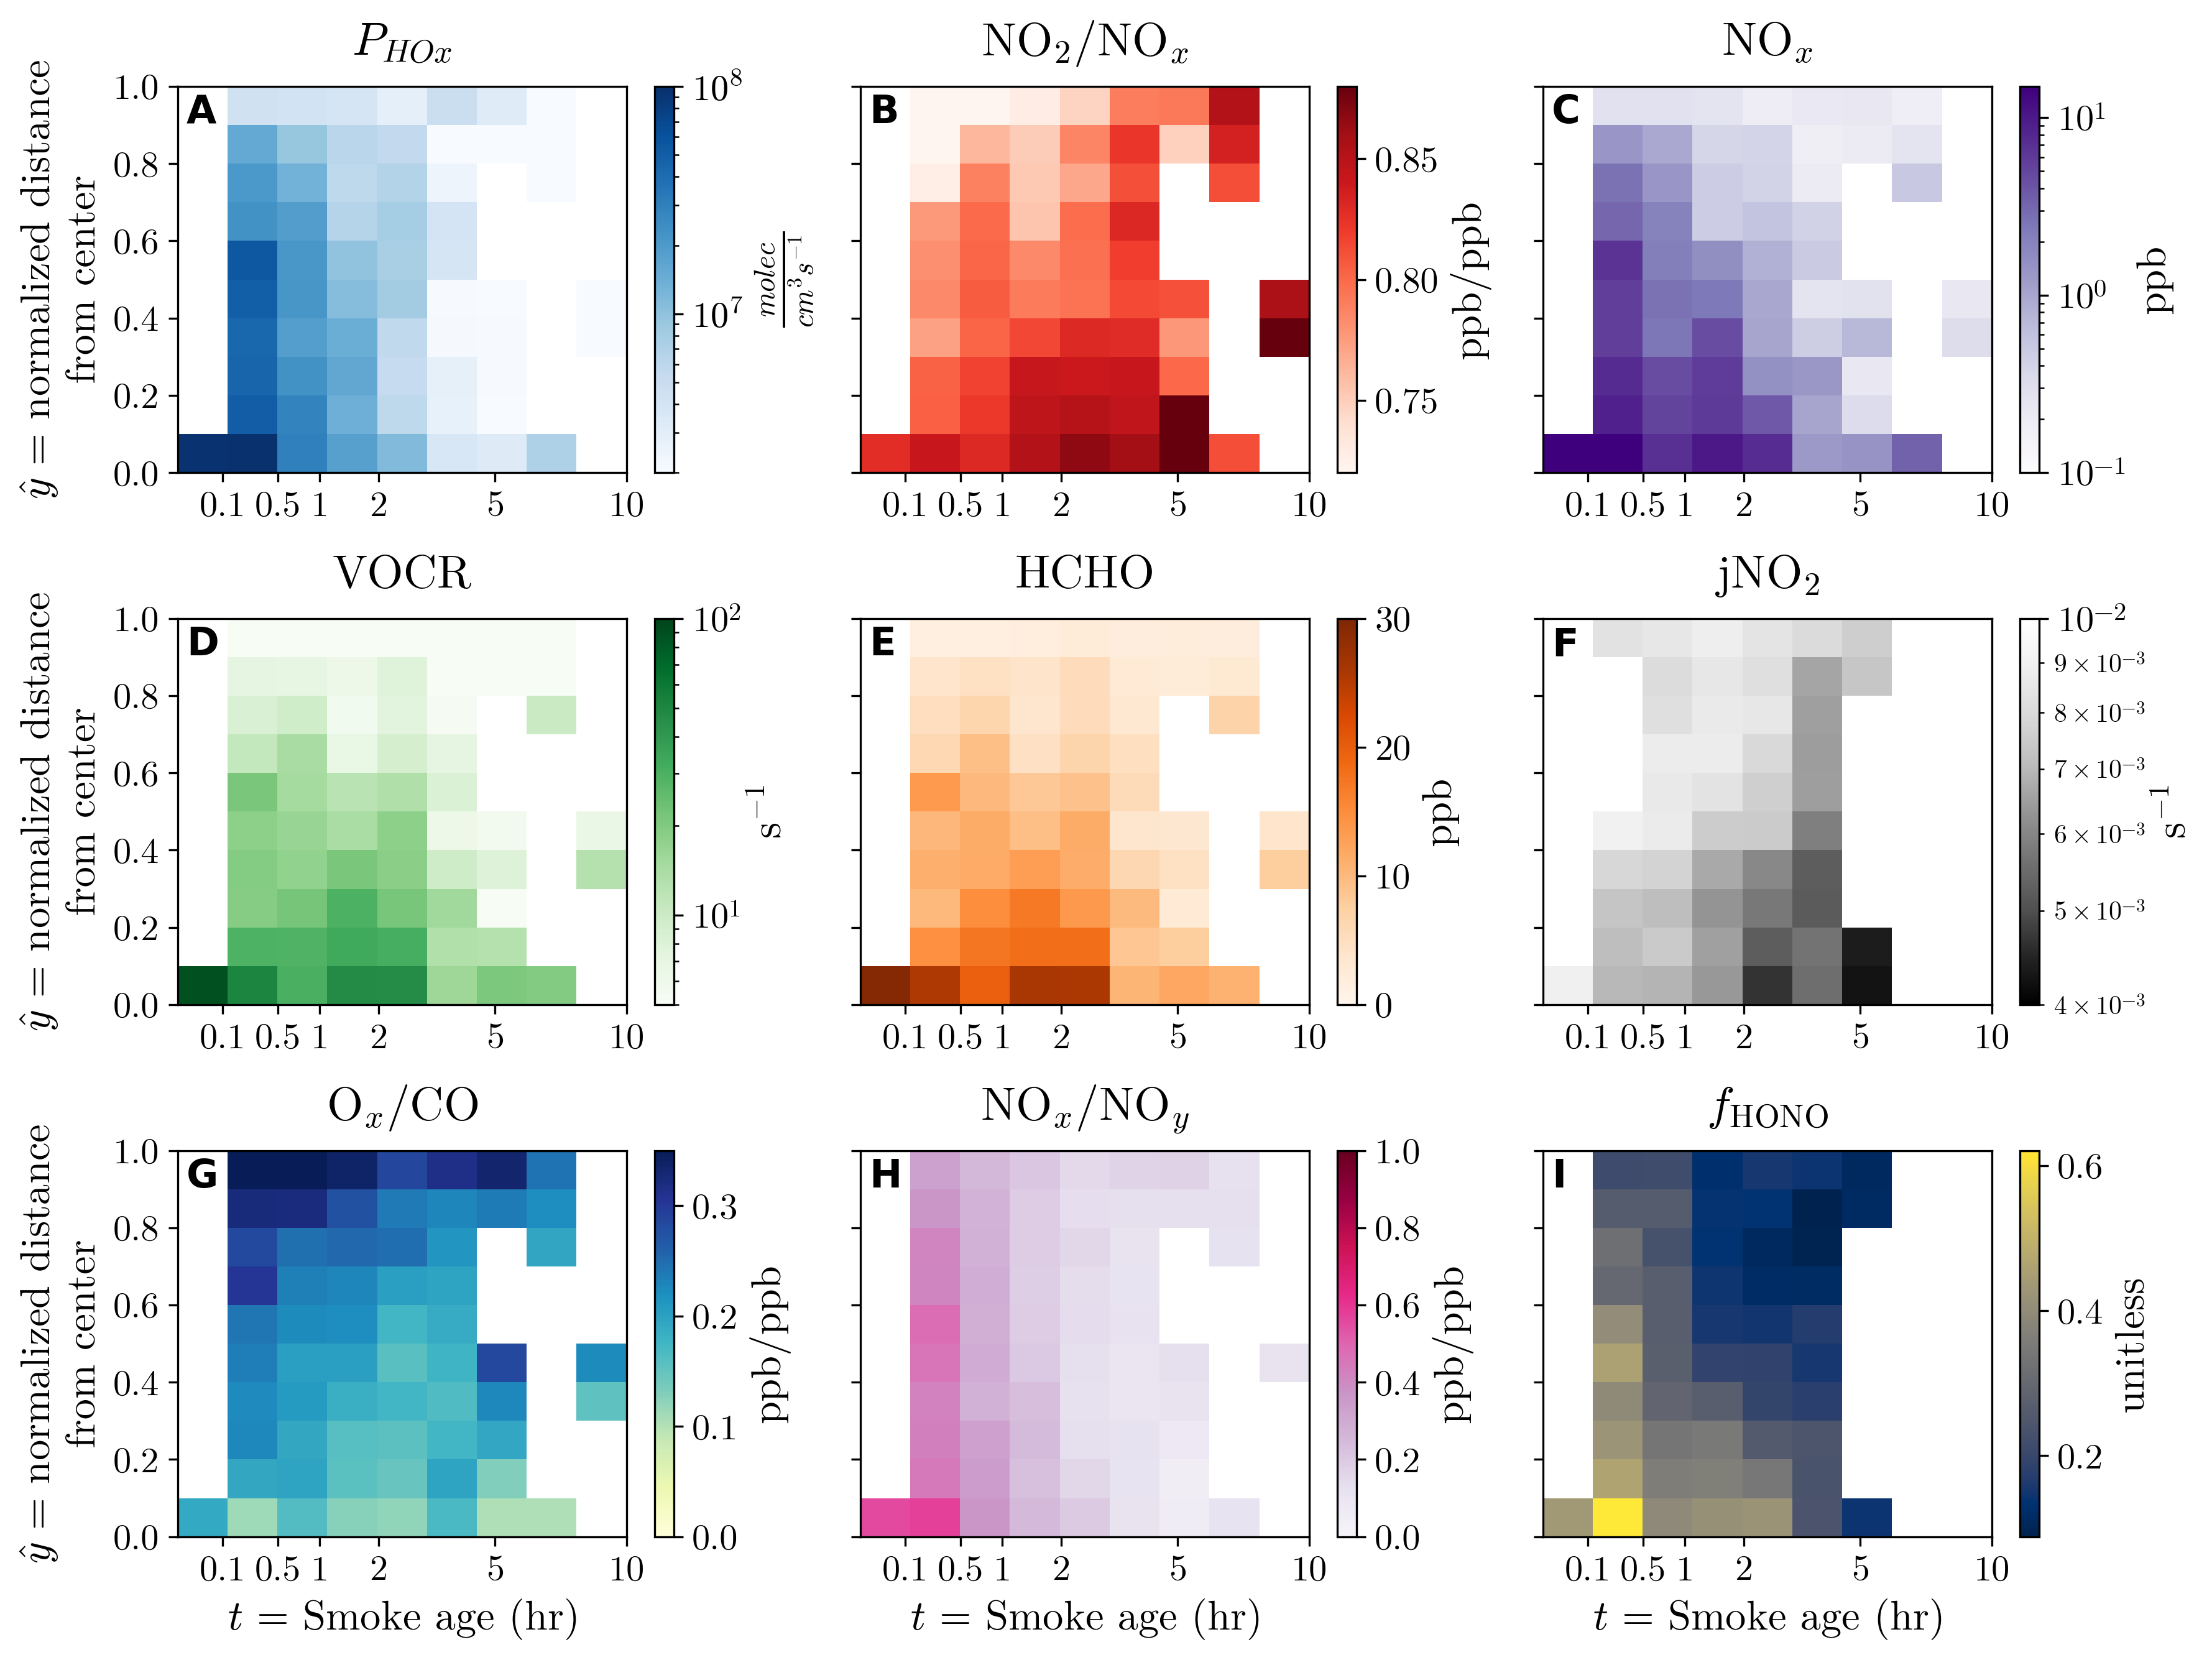

In [5]:
%matplotlib inline

import sys
from pathlib import Path

NB = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/notebooks")
if str(NB) not in sys.path:
    sys.path.insert(0, str(NB))

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

from plume import binned_mean, load_plume_table

df = load_plume_table()

fields = {
    "PHOx": 30,
    "NO2/NOx": 30,
    "NOx_ppb": 30,
    "VOCR": 30,
    "HCHO": 30,
    "jNO2": 50,
    "Ox/CO": 30,
    "NOx/NOy": 30,
    "f_hono": 30,
}
stats = {}
for column, min_count in fields.items():
    source = df
    if column == "f_hono":
        source = df[df["f_hono"] > 0]
    stat, x_edges, y_edges = binned_mean(source, column, min_count=min_count)
    stats[column] = stat

fig, ax = plt.subplots(3, 3, figsize=(12, 9), dpi=300)
ax = ax.flatten()

TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 14

cmap1 = plt.cm.Blues
norm1 = mcolors.LogNorm(vmin=2e6, vmax=1e8)
cmap2 = plt.cm.Reds
norm2 = mcolors.Normalize(vmin=0.72, vmax=0.88)
cmap3 = plt.cm.Purples
norm3 = mcolors.LogNorm(vmin=0.1, vmax=15)
cmap4 = plt.cm.Greens
norm4 = mcolors.LogNorm(vmin=5, vmax=100)
cmap5 = plt.cm.Oranges
norm5 = mcolors.Normalize(vmin=0, vmax=30)
cmap6 = plt.cm.Greys_r
norm6 = mcolors.LogNorm(vmin=4e-3, vmax=1e-2)
cmap7 = plt.cm.YlGnBu
norm7 = mcolors.Normalize(vmin=0, vmax=0.35)
cmap8 = plt.cm.PuRd
norm8 = mcolors.Normalize(vmin=0, vmax=1)
cmap9 = plt.cm.cividis
norm9 = None

def format_panel(a, ylabel=False, xlabel=False):
    if ylabel:
        a.set_ylabel(
            r"$\hat{y}$ = normalized distance" + "\n" + r"from center",
            fontsize=LABEL_SIZE,
        )
    else:
        a.set_yticklabels([])
    if xlabel:
        a.set_xlabel(r"$t$ = Smoke age (hr)", fontsize=LABEL_SIZE)
    a.set_xscale("function", functions=(np.sqrt, np.square))
    a.set_xticks([0.1, 0.5, 1, 2, 5, 10])
    a.set_xticklabels([0.1, 0.5, 1, 2, 5, 10])
    a.set_xlim(0, 10)
    a.tick_params(labelsize=TICK_SIZE)

pcm1 = ax[0].pcolormesh(x_edges, y_edges, stats["PHOx"].T, cmap=cmap1, shading="auto", norm=norm1)
cbar1 = fig.colorbar(pcm1, ax=ax[0])
cbar1.set_ticks([1e7, 1e8])
cbar1.ax.set_yticklabels([r"$10^7$", r"$10^8$"])
cbar1.ax.tick_params(labelsize=TICK_SIZE)
cbar1.set_label(r"$\frac{molec}{cm^{3}s^{-1}}$", fontsize=LABEL_SIZE)
ax[0].set_title(r"$P_{HOx}$", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[0], ylabel=True)

pcm2 = ax[1].pcolormesh(x_edges, y_edges, stats["NO2/NOx"].T, cmap=cmap2, shading="auto", norm=norm2)
cbar2 = fig.colorbar(pcm2, ax=ax[1])
cbar2.ax.tick_params(labelsize=TICK_SIZE)
cbar2.set_label(r"ppb/ppb", fontsize=LABEL_SIZE)
ax[1].set_title(r"NO$_2$/NO$_x$", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[1])

pcm3 = ax[2].pcolormesh(x_edges, y_edges, stats["NOx_ppb"].T, cmap=cmap3, shading="auto", norm=norm3)
cbar3 = fig.colorbar(pcm3, ax=ax[2])
cbar3.ax.tick_params(labelsize=TICK_SIZE)
cbar3.set_label(r"ppb", fontsize=LABEL_SIZE)
ax[2].set_title(r"NO$_x$", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[2])

pcm4 = ax[3].pcolormesh(x_edges, y_edges, stats["VOCR"].T, cmap=cmap4, shading="auto", norm=norm4)
cbar4 = fig.colorbar(pcm4, ax=ax[3])
cbar4.ax.tick_params(labelsize=TICK_SIZE)
cbar4.set_label(r"s$^{-1}$", fontsize=LABEL_SIZE)
ax[3].set_title(r"VOCR", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[3], ylabel=True)

pcm5 = ax[4].pcolormesh(x_edges, y_edges, stats["HCHO"].T, cmap=cmap5, shading="auto", norm=norm5)
cbar5 = fig.colorbar(pcm5, ax=ax[4])
cbar5.ax.tick_params(labelsize=TICK_SIZE)
cbar5.set_label(r"ppb", fontsize=LABEL_SIZE)
ax[4].set_title(r"HCHO", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[4])

pcm6 = ax[5].pcolormesh(x_edges, y_edges, stats["jNO2"].T, cmap=cmap6, shading="auto", norm=norm6)
cbar6 = fig.colorbar(pcm6, ax=ax[5])
cbar6.ax.tick_params(labelsize=TICK_SIZE)
cbar6.set_label(r"s$^{-1}$", fontsize=LABEL_SIZE)
ax[5].set_title(r"jNO$_2$", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[5])

pcm7 = ax[6].pcolormesh(x_edges, y_edges, stats["Ox/CO"].T, cmap=cmap7, shading="auto", norm=norm7)
cbar7 = fig.colorbar(pcm7, ax=ax[6])
cbar7.ax.tick_params(labelsize=TICK_SIZE)
cbar7.set_label(r"ppb/ppb", fontsize=LABEL_SIZE)
ax[6].set_title(r"O$_x$/CO", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[6], ylabel=True, xlabel=True)

pcm8 = ax[7].pcolormesh(x_edges, y_edges, stats["NOx/NOy"].T, cmap=cmap8, shading="auto", norm=norm8)
cbar8 = fig.colorbar(pcm8, ax=ax[7])
cbar8.ax.tick_params(labelsize=TICK_SIZE)
cbar8.set_label(r"ppb/ppb", fontsize=LABEL_SIZE)
ax[7].set_title(r"NO$_x$/NO$_y$", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[7], xlabel=True)

pcm9 = ax[8].pcolormesh(x_edges, y_edges, stats["f_hono"].T, cmap=cmap9, shading="auto", norm=norm9)
cbar9 = fig.colorbar(pcm9, ax=ax[8])
cbar9.ax.tick_params(labelsize=TICK_SIZE)
cbar9.set_label(r"unitless", fontsize=LABEL_SIZE)
ax[8].set_title(r"$f_{\mathrm{HONO}}$", fontsize=TITLE_SIZE, pad=12)
format_panel(ax[8], xlabel=True)

for letter, a in zip("ABCDEFGHI", ax):
    a.text(
        0.02, 0.98, letter,
        transform=a.transAxes,
        ha="left", va="top",
        fontsize=15,
        fontweight="bold",
        fontfamily="Arial",
    )

plt.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/fig02.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/fig02.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
